In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "raw"
    / "mcv_text_lid"
    / "mcv_text_lid.tsv"
)

df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    nrows=10
)

display(df)

,id,sentence,lang,sentence_domain,source,style,split
0,13914460,Il più grande di loro fu Giovanni evangelista.,it,NaN,wiki,scripted,train
1,7896754,The underground system develops in the limesto...,en,NaN,covost2-xx_en,scripted,train
2,10580213,À boire! répéta pour la troisième fois Qua...,fr,NaN,sentence-collector,scripted,test
3,14529549,岩手県宮古市,ja,NaN,?????,scripted,train
4,1076937,Y en ixas va alentar de segundas.,an,general,self,scripted,train
5,18424113,ข้อบังคับการประชุม,th,NaN,sentence-collector,scripted,train
6,6886961,He is a specialist in the economies of East As...,en,NaN,wiki,scripted,test
7,13289754,És akkor kap egy isteni fiút.,hu,NaN,wiki,scripted,train
8,1705364,У асобных раёнах прагназуецца невялікі снег.,be,NaN,euroradio-sampled-sentences-non-blacklisted,scripted,dev
9,2522690,Alguns podrien produir verins per a dissuadir ...,ca,NaN,covost2-ca,scripted,train


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               10 non-null     int64
 1   sentence         10 non-null     str  
 2   lang             10 non-null     str  
 3   sentence_domain  1 non-null      str  
 4   source           10 non-null     str  
 5   style            10 non-null     str  
 6   split            10 non-null     str  
dtypes: int64(1), str(6)
memory usage: 692.0 bytes


In [4]:
target_languages = ["tr", "en", "de", "fr"]

filtered_df = df[df["lang"].isin(target_languages)]

display(filtered_df)

,id,sentence,lang,sentence_domain,source,style,split
1,7896754,The underground system develops in the limesto...,en,NaN,covost2-xx_en,scripted,train
2,10580213,À boire! répéta pour la troisième fois Qua...,fr,NaN,sentence-collector,scripted,test
6,6886961,He is a specialist in the economies of East As...,en,NaN,wiki,scripted,test


In [5]:
# Orijinal veriyi değiştirmemek için kopyasını alıyoruz.
filtered_df = filtered_df.copy()

# Her metindeki kelime sayısını hesaplıyoruz.
filtered_df["word_count"] = (
    filtered_df["sentence"]
    .str.split()
    .str.len()
)

# İlgilendiğimiz sütunları gösteriyoruz.
display(filtered_df[["sentence", "lang", "word_count"]])

,sentence,lang,word_count
1,The underground system develops in the limesto...,en,13
2,À boire! répéta pour la troisième fois Qua...,fr,9
6,He is a specialist in the economies of East As...,en,12


In [6]:

from pathlib import Path
import pandas as pd

# Veri setinin yolu
DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "raw"
    / "mcv_text_lid"
    / "mcv_text_lid.tsv"
)

target_languages = ["tr", "en", "de", "fr"]

# Sütunlara göre eksik değerleri tutacağız.
null_counts = pd.Series(dtype="int64")

total_rows = 0
empty_sentence_count = 0

for chunk in pd.read_csv(
    DATA_PATH,
    sep="\t",
    chunksize=50000
):
    # Sadece seçtiğimiz dört dili inceliyoruz.
    chunk = chunk[
        chunk["lang"].isin(target_languages)
    ]

    total_rows += len(chunk)

    # Her sütunun eksik değerlerini say.
    counts = chunk.isna().sum()
    null_counts = null_counts.add(
        counts, fill_value=0
    )

    # Null olmayan fakat boşluklardan oluşan metinler.
    empty_sentence_count += (
        chunk["sentence"]
        .fillna("")
        .str.strip()
        .eq("")
        .sum()
    )

# Sonuç tablosu
null_result = pd.DataFrame({
    "Null Sayısı": null_counts.astype(int),
})

null_result["Null Oranı (%)"] = (
    null_result["Null Sayısı"] / total_rows * 100
).round(2)

display(null_result)

print("Toplam incelenen kayıt:", total_rows)
print(
    "Boş veya yalnızca boşluk içeren metin:",
    empty_sentence_count
)


,Null Sayısı,Null Oranı (%)
id,0,0.00
lang,0,0.00
sentence,0,0.00
sentence_domain,5788975,99.96
source,33804,0.58
split,0,0.00
style,0,0.00


Toplam incelenen kayıt: 5791076
Boş veya yalnızca boşluk içeren metin: 0


In [7]:
# Aynı metnin tekrar edip etmediğini kontrol et
duplicate_mask = df.duplicated(
    subset=["sentence"],
    keep=False
)

# Tekrar eden metinleri göster
display(df[duplicate_mask])

,id,sentence,lang,sentence_domain,source,style,split


In [8]:
df.shape

(10, 7)

In [9]:
import pandas as pd
from pathlib import Path

DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "sampled_dataset.csv"
)

sampled_df = pd.read_csv(DATA_PATH)

print("Veri boyutu:", sampled_df.shape)
display(sampled_df.head())

Veri boyutu: (40000, 4)


,id,sentence,lang,split
0,10631671,"Ce bâtiment, construit en béton armé, inclut s...",fr,train
1,7698467,The district between this promontory and Otran...,en,train
2,5958778,Neben dem Sachsenspiegel sind bayerische Quell...,de,dev
3,18557417,Açık döngü sistemler genellikle daha ucuzdur a...,tr,train
4,4784787,Das wäre sonst ein ganzes Buch geworden.,de,train


In [10]:
# Aynı metne sahip fazladan kayıtlar
duplicate_count = sampled_df.duplicated(
    subset=["sentence"]
).sum()

# Aynı metin + aynı dil tekrarları
same_language_duplicates = sampled_df.duplicated(
    subset=["sentence", "lang"]
).sum()

print("Tekrar eden fazladan kayıt:", duplicate_count)
print("Aynı metin ve dil tekrarları:", same_language_duplicates)

Tekrar eden fazladan kayıt: 0
Aynı metin ve dil tekrarları: 0


In [11]:
train_texts = set(
    sampled_df.loc[
        sampled_df["split"] == "train", "sentence"
    ]
)

dev_texts = set(
    sampled_df.loc[
        sampled_df["split"] == "dev", "sentence"
    ]
)

test_texts = set(
    sampled_df.loc[
        sampled_df["split"] == "test", "sentence"
    ]
)

print("Train - Dev çakışması:",
      len(train_texts & dev_texts))

print("Train - Test çakışması:",
      len(train_texts & test_texts))

print("Dev - Test çakışması:",
      len(dev_texts & test_texts))

Train - Dev çakışması: 0
Train - Test çakışması: 0
Dev - Test çakışması: 0


In [13]:
import unicodedata

def normalize_for_duplicate(text):
    # Unicode gösterimini standartlaştır.
    text = unicodedata.normalize("NFC", str(text))

    # Büyük/küçük harf farklarını azalt.
    text = text.casefold()

    # Fazladan boşlukları temizle.
    text = " ".join(text.split())

    return text


sampled_df["normalized_sentence"] = (
    sampled_df["sentence"].apply(normalize_for_duplicate)
)

# Normalizasyon sonrası fazladan tekrarlar
normalized_duplicates = sampled_df.duplicated(
    subset=["normalized_sentence"]
).sum()

print("Normalizasyon sonrası duplicate:", normalized_duplicates)

# Bölümler arasındaki çakışmalar
groups = {
    split: set(
        sampled_df.loc[
            sampled_df["split"] == split,
            "normalized_sentence"
        ]
    )
    for split in ["train", "dev", "test"]
}

print("Train - Dev:", len(groups["train"] & groups["dev"]))
print("Train - Test:", len(groups["train"] & groups["test"]))
print("Dev - Test:", len(groups["dev"] & groups["test"]))

Normalizasyon sonrası duplicate: 0
Train - Dev: 0
Train - Test: 0
Dev - Test: 0


In [16]:
sampled_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   id                   40000 non-null  int64
 1   sentence             40000 non-null  str  
 2   lang                 40000 non-null  str  
 3   split                40000 non-null  str  
 4   normalized_sentence  40000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB


In [17]:
# Orijinal DataFrame'i değiştirmiyoruz.
length_df = sampled_df.copy()

# Metinlerin kelime sayısını hesaplıyoruz.
length_df["word_count"] = (
    length_df["sentence"].str.split().str.len()
)

# Kelime sayılarını kategorilere ayırıyoruz.
length_df["length_group"] = pd.cut(
    length_df["word_count"],
    bins=[0, 3, 7, 15, float("inf")],
    labels=["1-3", "4-7", "8-15", "16+"]
)

# Her dilde kaç kayıt bulunduğunu hesaplıyoruz.
length_table = pd.crosstab(
    length_df["lang"],
    length_df["length_group"]
)

display(length_table)

length_group,1-3,4-7,8-15,16+
lang,,,,
de,155,2441,7398,6
en,88,1764,8122,26
fr,107,2004,7884,5
tr,807,3841,5099,253


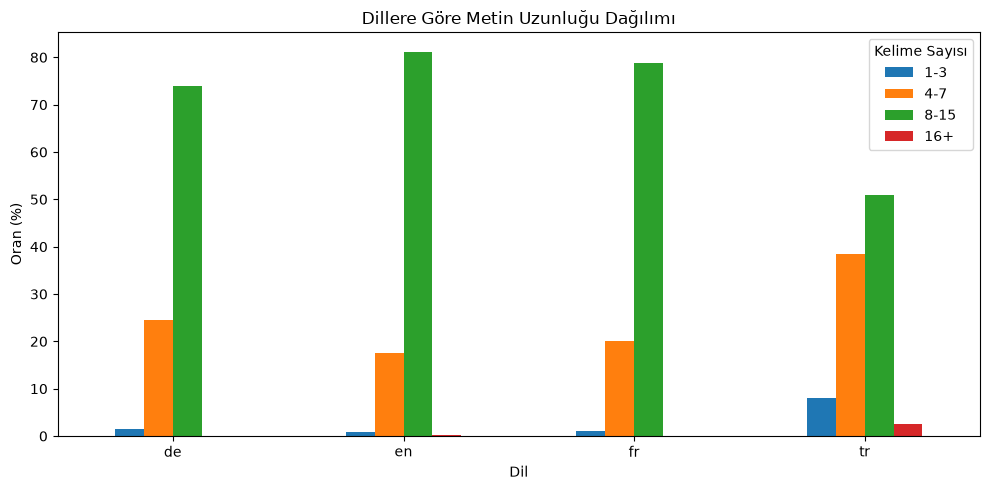

In [19]:
import matplotlib.pyplot as plt

# Dil başına yüzdelik dağılım
length_percent = length_table.div(
    length_table.sum(axis=1),
    axis=0
) * 100

length_percent.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Dillere Göre Metin Uzunluğu Dağılımı")
plt.xlabel("Dil")
plt.ylabel("Oran (%)")
plt.xticks(rotation=0)
plt.legend(title="Kelime Sayısı")
plt.tight_layout()
plt.show()